# Statistical Hypothesis Testing: Lunch vs Dinner Tipping Behaviour

**Milestone:** Statistical Hypothesis Testing  
**Tools:** Python, Pandas, NumPy, SciPy, Matplotlib, Seaborn, Google Colab  
**Dataset:** Seaborn Tips dataset (244 restaurant transactions)

## Project objective
This notebook tests whether the **mean tip percentage** differs between lunch and dinner transactions. It follows a complete statistical workflow: define hypotheses, inspect the data, check assumptions, choose and run an appropriate test, quantify the size of the difference, and explain the result in plain English.

> **Research question:** Is the average tip percentage different for lunch and dinner transactions?

The dataset is a real, commonly used restaurant-transactions dataset. It is small and relatively tidy, so this project focuses on statistical inference rather than pretending the dataset has quality problems it does not contain.


## 1. State the hypotheses before testing

Let μL be the population mean tip percentage for lunch transactions and μD the population mean tip percentage for dinner transactions.

- **Null hypothesis (H₀):** μL = μD. There is no difference in mean tip percentage between lunch and dinner.
- **Alternative hypothesis (H₁):** μL ≠ μD. There is a difference in mean tip percentage between lunch and dinner.

We use a **two-sided test** because we are asking whether the means differ, not assuming in advance which dining period has the higher mean.

**Significance level:** α = 0.05. If the p-value is below 0.05, we reject H₀. Otherwise, we fail to reject H₀. A p-value is not the probability that H₀ is true.


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the real dataset

The Seaborn Tips dataset contains restaurant bills, tip amounts, dining period, day, party size, and other transaction details. We calculate **tip percentage** as `tip / total_bill × 100`. This normalises the tip amount relative to the bill, making transactions with different bill sizes more comparable.

Source: [Seaborn Tips dataset on GitHub](https://github.com/mwaskom/seaborn-data/blob/master/tips.csv).


In [2]:
# Load directly from the public dataset source
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

# Create the outcome variable used in the hypothesis test
df["tip_pct"] = (df["tip"] / df["total_bill"]) * 100

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn data types:")
display(df.dtypes)


Dataset shape: (244, 8)


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


\nColumn data types:


,0
total_bill,float64
tip,float64
sex,object
smoker,object
day,object
time,object
size,int64
tip_pct,float64


## 3. Understand the data and define the two groups

We compare independent transactions from the `Lunch` and `Dinner` groups. The outcome is continuous (`tip_pct`) and the grouping variable has two independent categories (`time`). Therefore, a two-independent-samples mean comparison is appropriate.

The standard independent-samples t-test assumes equal population variances. We will use **Welch's independent-samples t-test**, which does not require equal variances and is a sensible default for two independent groups.


In [3]:
print("Dining-period counts:")
display(df["time"].value_counts())

print("\\nSummary statistics for tip percentage:")
display(df.groupby("time")["tip_pct"].agg(["count", "mean", "std", "median", "min", "max"]))

lunch = df.loc[df["time"] == "Lunch", "tip_pct"].dropna()
dinner = df.loc[df["time"] == "Dinner", "tip_pct"].dropna()

print(f"\nLunch observations: {len(lunch)}")
print(f"Dinner observations: {len(dinner)}")


Dining-period counts:


,count
time,
Dinner,176
Lunch,68


\nSummary statistics for tip percentage:


,count,mean,std,median,min,max
time,,,,,,
Dinner,176,15.951779,6.747714,15.540002,3.563814,71.034483
Lunch,68,16.412793,4.024155,15.408357,7.296137,26.631158



Lunch observations: 68
Dinner observations: 176


## 4. Visual inspection

Histograms and box plots help us inspect distribution shape, spread, and potential extreme observations. Visual inspection does not prove assumptions, but it helps identify issues that a single test statistic might hide.


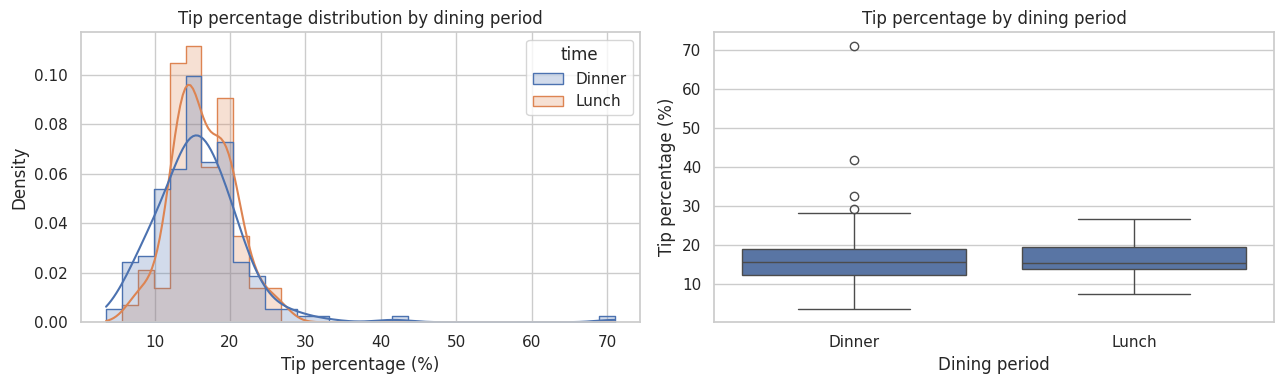

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=df, x="tip_pct", hue="time", kde=True, element="step",
             stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Tip percentage distribution by dining period")
axes[0].set_xlabel("Tip percentage (%)")

sns.boxplot(data=df, x="time", y="tip_pct", ax=axes[1])
axes[1].set_title("Tip percentage by dining period")
axes[1].set_xlabel("Dining period")
axes[1].set_ylabel("Tip percentage (%)")

plt.tight_layout()
plt.show()


## 5. Check the assumptions and limitations

For an independent-samples t-test, we consider:

1. **Independence:** Each row represents a transaction. We assume transactions are independent; the dataset does not provide customer IDs to test repeated customers. This is a design assumption, not something normality tests can verify.
2. **Continuous outcome:** Tip percentage is numerical and continuous.
3. **Distribution shape / normality:** We inspect histograms and use Shapiro–Wilk tests within each group. With moderate samples, the t-test is often reasonably robust to modest non-normality, but strong skew or influential outliers deserves caution.
4. **Equal variances:** Welch's t-test does not assume equal variances. We report Levene's test as a diagnostic, not as a gate that determines which test to run.
5. **Sampling / generalisability:** The dataset is a limited sample and may not represent all restaurants, regions, or time periods. Statistical significance does not establish causation.


In [5]:
# Shapiro-Wilk normality checks (applied to each group's observed values)
shapiro_lunch = stats.shapiro(lunch)
shapiro_dinner = stats.shapiro(dinner)

# Levene's test checks whether group variances differ
levene_result = stats.levene(lunch, dinner, center="median")

assumption_results = pd.DataFrame({
    "Check": ["Shapiro-Wilk: Lunch", "Shapiro-Wilk: Dinner", "Levene's test"],
    "Statistic": [shapiro_lunch.statistic, shapiro_dinner.statistic, levene_result.statistic],
    "p-value": [shapiro_lunch.pvalue, shapiro_dinner.pvalue, levene_result.pvalue]
})
display(assumption_results)

print("Interpretation at alpha = 0.05:")
print(f"Lunch Shapiro p-value: {shapiro_lunch.pvalue:.6g}")
print(f"Dinner Shapiro p-value: {shapiro_dinner.pvalue:.6g}")
print(f"Levene p-value: {levene_result.pvalue:.6g}")
print("A small Shapiro p-value indicates evidence against a normal distribution.")
print("A small Levene p-value indicates evidence that the group variances differ.")
print("Welch's t-test is used regardless of Levene's result because it does not require equal variances.")


,Check,Statistic,p-value
0,Shapiro-Wilk: Lunch,0.983080,4.851810e-01
1,Shapiro-Wilk: Dinner,0.775261,3.759562e-15
2,Levene's test,2.432644,1.201391e-01


Interpretation at alpha = 0.05:
Lunch Shapiro p-value: 0.485181
Dinner Shapiro p-value: 3.75956e-15
Levene p-value: 0.120139
A small Shapiro p-value indicates evidence against a normal distribution.
A small Levene p-value indicates evidence that the group variances differ.
Welch's t-test is used regardless of Levene's result because it does not require equal variances.


## 6. Run the statistical hypothesis test

**Chosen test: Welch's two-sided independent-samples t-test (`scipy.stats.ttest_ind` with `equal_var=False`).**

**Why this test fits:** The outcome (`tip_pct`) is continuous, the groups (Lunch and Dinner) are independent, and the question compares two population means. Welch's version is robust to unequal group variances.

We also calculate a 95% confidence interval for the difference in means (Lunch − Dinner), using the Welch–Satterthwaite degrees of freedom. The interval helps show the range of plausible differences in the population mean.


In [6]:
alpha = 0.05

welch = stats.ttest_ind(lunch, dinner, equal_var=False, alternative="two-sided")

n1, n2 = len(lunch), len(dinner)
mean_lunch, mean_dinner = lunch.mean(), dinner.mean()
var_lunch, var_dinner = lunch.var(ddof=1), dinner.var(ddof=1)

# Welch standard error and degrees of freedom
se_diff = np.sqrt(var_lunch / n1 + var_dinner / n2)
df_welch = (var_lunch / n1 + var_dinner / n2) ** 2 / (
    (var_lunch / n1) ** 2 / (n1 - 1) +
    (var_dinner / n2) ** 2 / (n2 - 1)
)

mean_diff = mean_lunch - mean_dinner
critical_t = stats.t.ppf(1 - alpha / 2, df_welch)
ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

print(f"Mean tip percentage - Lunch:  {mean_lunch:.3f}%")
print(f"Mean tip percentage - Dinner: {mean_dinner:.3f}%")
print(f"Mean difference (Lunch - Dinner): {mean_diff:.3f} percentage points")
print(f"Welch t-statistic: {welch.statistic:.4f}")
print(f"Welch degrees of freedom: {df_welch:.2f}")
print(f"Two-sided p-value: {welch.pvalue:.6g}")
print(f"95% confidence interval for mean difference: [{ci_low:.3f}, {ci_high:.3f}] percentage points")

if welch.pvalue < alpha:
    print("\\nDecision: Reject the null hypothesis at alpha = 0.05.")
else:
    print("\\nDecision: Fail to reject the null hypothesis at alpha = 0.05.")


Mean tip percentage - Lunch:  16.413%
Mean tip percentage - Dinner: 15.952%
Mean difference (Lunch - Dinner): 0.461 percentage points
Welch t-statistic: 0.6540
Welch degrees of freedom: 200.88
Two-sided p-value: 0.513836
95% confidence interval for mean difference: [-0.929, 1.851] percentage points
\nDecision: Fail to reject the null hypothesis at alpha = 0.05.


## 7. Practical significance: how large is the difference?

A statistically significant result does not automatically mean the difference is important in business terms. We calculate **Cohen's d** as a standardised effect-size measure. Because Welch's test allows unequal variances, Cohen's d here is a descriptive pooled-standard-deviation effect size rather than the basis of the test decision.

We also inspect the raw difference in percentage points. A small difference may be statistically detectable but have limited practical value. The dataset alone cannot tell us whether a difference changes restaurant revenue or customer behaviour enough to justify a business decision.


In [7]:
# Cohen's d using the conventional pooled standard deviation
pooled_sd = np.sqrt(((n1 - 1) * var_lunch + (n2 - 1) * var_dinner) / (n1 + n2 - 2))
cohens_d = mean_diff / pooled_sd

print(f"Cohen's d (Lunch - Dinner): {cohens_d:.3f}")
print(f"Absolute mean difference: {abs(mean_diff):.3f} percentage points")

if abs(cohens_d) < 0.2:
    effect_label = "very small / negligible"
elif abs(cohens_d) < 0.5:
    effect_label = "small"
elif abs(cohens_d) < 0.8:
    effect_label = "medium"
else:
    effect_label = "large"

print("Approximate standardised effect size:", effect_label)


Cohen's d (Lunch - Dinner): 0.075
Absolute mean difference: 0.461 percentage points
Approximate standardised effect size: very small / negligible


## 8. Optional robustness check: Mann–Whitney U test

The Mann–Whitney U test is a non-parametric comparison of two independent groups. It does not test equality of means; it tests for a difference in distributions (and can be interpreted as a location/rank comparison under additional assumptions). We use it only as a sensitivity check because the primary research question is about means and the primary test remains Welch's t-test.

If the two tests differ, report that as a caveat rather than selecting whichever result is more convenient.


In [8]:
mw = stats.mannwhitneyu(lunch, dinner, alternative="two-sided")
print(f"Mann-Whitney U statistic: {mw.statistic:.3f}")
print(f"Mann-Whitney two-sided p-value: {mw.pvalue:.6g}")
print("This is a sensitivity analysis; it does not replace the pre-specified Welch mean comparison.")


Mann-Whitney U statistic: 6577.500
Mann-Whitney two-sided p-value: 0.230278
This is a sensitivity analysis; it does not replace the pre-specified Welch mean comparison.


## 9. Automated findings report

The following cell generates a plain-English report using the actual statistics calculated above. Run the notebook from top to bottom before using the report in your submission.


In [11]:

decision = (
    "reject the null hypothesis"
    if welch.pvalue < alpha
    else "fail to reject the null hypothesis"
)

direction = (
    "higher"
    if mean_diff > 0
    else "lower"
    if mean_diff < 0
    else "the same"
)

report = f"""
# Statistical Findings Report: Lunch vs Dinner Tip Percentage

## Research question
Is the mean tip percentage different between lunch and dinner transactions?

## Hypotheses
- **H₀:** The population mean tip percentage is equal for lunch and dinner.
- **H₁:** The population mean tip percentage differs between lunch and dinner.

## Method
The analysis used the Seaborn Tips dataset. Tip percentage was calculated as tip divided by total bill, multiplied by 100. Since the outcome is continuous and the two dining-period groups are independent, Welch's two-sided independent-samples t-test was selected. Welch's test does not require equal group variances.

## Assumption checks
- Lunch Shapiro–Wilk p-value: **{shapiro_lunch.pvalue:.6g}**
- Dinner Shapiro–Wilk p-value: **{shapiro_dinner.pvalue:.6g}**
- Levene's test p-value: **{levene_result.pvalue:.6g}**

The Shapiro–Wilk results assess evidence against normality within each group. Levene's test assesses variance equality. Welch's test was used because it does not assume equal variances. Independence is assumed from the transaction-level structure and cannot be verified from the available columns. The dataset is limited, so findings should not automatically be generalised to all restaurants.

## Results
- Lunch sample size: **{n1}**
- Dinner sample size: **{n2}**
- Lunch mean tip percentage: **{mean_lunch:.3f}%**
- Dinner mean tip percentage: **{mean_dinner:.3f}%**
- Mean difference (Lunch − Dinner): **{mean_diff:.3f} percentage points**
- Welch t-statistic: **{welch.statistic:.4f}**
- Welch degrees of freedom: **{df_welch:.2f}**
- Two-sided p-value: **{welch.pvalue:.6g}**
- 95% confidence interval for the mean difference: **[{ci_low:.3f}, {ci_high:.3f}] percentage points**
- Cohen's d: **{cohens_d:.3f}** ({effect_label} approximate standardised effect)

## Decision at α = 0.05
Because the p-value is **{welch.pvalue:.6g}**, we **{decision}**.

## Plain-English conclusion
In this sample, the average lunch tip percentage is {direction} than the average dinner tip percentage by {abs(mean_diff):.3f} percentage points. At the 5% significance level, the test result means we {decision}. This is evidence about a difference in population means under the test assumptions; it does not prove that dining period causes the difference.

## Statistical versus practical significance
The p-value addresses whether the observed evidence is inconsistent with equal population means. Practical significance depends on the size of the difference and whether it matters operationally. The observed difference is {abs(mean_diff):.3f} percentage points, with an approximate Cohen's d of {cohens_d:.3f}. A restaurant should consider its transaction volume, margins, and business context before treating this difference as actionable.

## Limitations
The dataset has 244 transactions and may not represent restaurants generally. Independence is assumed, customer-level clustering cannot be assessed, and the dataset is observational. The analysis identifies an association, not causation.
"""

display(Markdown(report))



# Statistical Findings Report: Lunch vs Dinner Tip Percentage

## Research question
Is the mean tip percentage different between lunch and dinner transactions?

## Hypotheses
- **H₀:** The population mean tip percentage is equal for lunch and dinner.
- **H₁:** The population mean tip percentage differs between lunch and dinner.

## Method
The analysis used the Seaborn Tips dataset. Tip percentage was calculated as tip divided by total bill, multiplied by 100. Since the outcome is continuous and the two dining-period groups are independent, Welch's two-sided independent-samples t-test was selected. Welch's test does not require equal group variances.

## Assumption checks
- Lunch Shapiro–Wilk p-value: **0.485181**
- Dinner Shapiro–Wilk p-value: **3.75956e-15**
- Levene's test p-value: **0.120139**

The Shapiro–Wilk results assess evidence against normality within each group. Levene's test assesses variance equality. Welch's test was used because it does not assume equal variances. Independence is assumed from the transaction-level structure and cannot be verified from the available columns. The dataset is limited, so findings should not automatically be generalised to all restaurants.

## Results
- Lunch sample size: **68**
- Dinner sample size: **176**
- Lunch mean tip percentage: **16.413%**
- Dinner mean tip percentage: **15.952%**
- Mean difference (Lunch − Dinner): **0.461 percentage points**
- Welch t-statistic: **0.6540**
- Welch degrees of freedom: **200.88**
- Two-sided p-value: **0.513836**
- 95% confidence interval for the mean difference: **[-0.929, 1.851] percentage points**
- Cohen's d: **0.075** (very small / negligible approximate standardised effect)

## Decision at α = 0.05
Because the p-value is **0.513836**, we **fail to reject the null hypothesis**.

## Plain-English conclusion
In this sample, the average lunch tip percentage is higher than the average dinner tip percentage by 0.461 percentage points. At the 5% significance level, the test result means we fail to reject the null hypothesis. This is evidence about a difference in population means under the test assumptions; it does not prove that dining period causes the difference.

## Statistical versus practical significance
The p-value addresses whether the observed evidence is inconsistent with equal population means. Practical significance depends on the size of the difference and whether it matters operationally. The observed difference is 0.461 percentage points, with an approximate Cohen's d of 0.075. A restaurant should consider its transaction volume, margins, and business context before treating this difference as actionable.

## Limitations
The dataset has 244 transactions and may not represent restaurants generally. Independence is assumed, customer-level clustering cannot be assessed, and the dataset is observational. The analysis identifies an association, not causation.


## 10. Export the report and supporting results

This cell saves the findings report as a Markdown file and the group-level summary as a CSV. These files can be uploaded alongside the notebook in your public GitHub repository.


In [12]:
# Save report as Markdown
with open("hypothesis_testing_report.md", "w", encoding="utf-8") as f:
    f.write(report)

# Save descriptive statistics and test results
summary = df.groupby("time")["tip_pct"].agg(
    sample_size="count", mean_tip_pct="mean", std_tip_pct="std", median_tip_pct="median"
).reset_index()
summary.to_csv("group_summary.csv", index=False)

test_results = pd.DataFrame([{
    "test": "Welch independent-samples t-test (two-sided)",
    "alpha": alpha,
    "t_statistic": welch.statistic,
    "degrees_of_freedom": df_welch,
    "p_value": welch.pvalue,
    "mean_difference_lunch_minus_dinner": mean_diff,
    "ci_95_lower": ci_low,
    "ci_95_upper": ci_high,
    "cohens_d": cohens_d,
    "decision": decision
}])
test_results.to_csv("test_results.csv", index=False)

print("Saved: hypothesis_testing_report.md, group_summary.csv, test_results.csv")


Saved: hypothesis_testing_report.md, group_summary.csv, test_results.csv


## 11. Final conclusion

This project demonstrates how to move from a visual impression to a statistical conclusion. The hypothesis was specified before testing, the test was selected to match a continuous outcome and two independent groups, assumptions and limitations were acknowledged, and both statistical and practical significance were considered.

**Submission reminder:** Run all cells in order, inspect the generated report, and upload the executed notebook plus `hypothesis_testing_report.md` to a public GitHub repository. Do not report numerical results from memory or from an unexecuted notebook; use the values produced by your own run.
